# 06 · Modelagem e validação

Treina e compara o baseline, o KNN, os dois Naive Bayes e a árvore de decisão nos dois cenários de atributos. Os hiperparâmetros são ajustados por validação cruzada estratificada no treino, e cada modelo final é avaliado no conjunto de teste.

In [1]:
%load_ext autoreload
%autoreload 2

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scroll_sono.config import FEATURE_SETS, FIGURES_DIR, RESULTS_PATH, TARGET, TARGET_CLASSES
from scroll_sono.data import load_test, load_train
from scroll_sono.evaluation import (METRIC_NAMES, REFIT, SCENARIO_COLORS, SCORING, cv_scores, grid_search,
                                    ignore_bin_warnings, make_cv, plot_confusion_matrix, plot_cv_comparison,
                                    test_scores)
from scroll_sono.models import MODEL_NAMES, PARAM_GRIDS, build_pipeline

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

In [2]:
# Estilo dos gráficos (o mesmo da EDA)
SUPERFICIE, TEXTO, TEXTO_SECUNDARIO, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "text.color": TEXTO, "axes.labelcolor": TEXTO_SECUNDARIO, "axes.edgecolor": "#c3c2b7",
    "xtick.color": TEXTO_SECUNDARIO, "ytick.color": TEXTO_SECUNDARIO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titlelocation": "left", "figure.titlesize": 12,
    "font.size": 9, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def salvar(fig, nome: str) -> None:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{nome}.png")

In [3]:
train = load_train()
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
print(f"Treino: {X_train.shape[0]:,} linhas × {X_train.shape[1]} colunas")

Treino: 6,800 linhas × 17 colunas


## 1. Estratégia de validação

- **Validação cruzada estratificada com 10 folds**, só no treino. Cada fold tem 680 registros, cerca de 52 deles de `Severe Sleep Debt`, e as estimativas ficam mais estáveis do que com 5 folds.
- **Os mesmos folds para todos:** `make_cv()` usa `shuffle=True` com `random_state` fixo, então a divisão é idêntica para todos os modelos, combinações de hiperparâmetros e cenários. As diferenças entre os resultados vêm dos modelos, não da sorte na divisão.
- **Métricas:** acurácia, acurácia balanceada (a média do acerto de cada classe) e F1 macro (a média do F1 de cada classe). Com 52,5% dos registros em `Moderate Debt`, um modelo que só prevê essa classe já tem 52,5% de acurácia; as outras duas métricas dão o mesmo peso às quatro classes.
- **Critério de escolha dos hiperparâmetros: F1 macro.** Assim como a acurácia balanceada, ele não favorece a classe majoritária, mas também penaliza os falsos positivos: um modelo que prevê `Severe Sleep Debt` demais tem a acurácia balanceada alta, mas o F1 dessa classe cai.
- **Pré-processamento dentro do pipeline:** em cada fold, o `GridSearchCV` ajusta o pré-processamento e o modelo só na parte de treino do fold, e avalia na parte restante.

Proporção das classes na parte de validação de cada fold:

In [4]:
cv = make_cv()
proporcoes = pd.DataFrame(
    {f"fold {i}": y_train.iloc[validacao].value_counts(normalize=True)
     for i, (_, validacao) in enumerate(cv.split(X_train, y_train), start=1)}
).reindex(TARGET_CLASSES)
(100 * proporcoes).round(1)

,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,fold 10
sleep_debt_category,,,,,,,,,,
Optimal Recovery,16.3,16.3,16.3,16.3,16.3,16.3,16.3,16.3,16.3,16.3
Mild Deficit,23.7,23.7,23.7,23.5,23.5,23.5,23.5,23.5,23.5,23.5
Moderate Debt,52.5,52.5,52.4,52.5,52.5,52.5,52.5,52.5,52.5,52.5
Severe Sleep Debt,7.5,7.5,7.6,7.6,7.6,7.6,7.6,7.6,7.6,7.6


## 2. Modelos e hiperparâmetros

| Modelo | Pré-processamento (etapa 5) | Hiperparâmetros testados |
|---|---|---|
| Baseline (`DummyClassifier`) | Nenhum efeito: ignora os atributos | Sempre prevê a classe mais frequente |
| KNN | `log1p` opcional, z-score ou min-max, one-hot | `log1p`, escala, `n_neighbors` (1 a 101), `weights` (uniforme ou pela distância) |
| Naive Bayes Gaussiano | `log1p` opcional, one-hot | `log1p`, `var_smoothing` (10⁻⁹ a 1) |
| Naive Bayes Categórico | Numéricas em faixas por quantis | `n_bins` (3 a 20), `alpha` (0,001 a 2) |
| Árvore de Decisão | Numéricas sem transformação, cronotipo ordinal, nominais em códigos inteiros ou one-hot | Codificação das nominais, `max_depth` (3 a 15 e sem limite), `min_samples_leaf` (1 a 100), `class_weight` (nenhum ou `"balanced"`) |

- As opções do pré-processamento entram na busca como hiperparâmetros (`prep__log_transform`, `prep__scaler`, `prep__n_bins`, `prep__nominal_encoding`), graças à classe `Preprocessor`. Cada combinação é avaliada com o pré-processamento refeito em cada fold.
- `weights="distance"` faz os vizinhos mais próximos pesarem mais no voto do KNN.
- `var_smoothing` soma às variâncias uma fração da maior variância, o que evita probabilidades extremas quando um atributo varia pouco numa classe.
- `alpha` é a suavização de Laplace do Naive Bayes Categórico: evita probabilidade zero para uma faixa que não aparece numa classe.
- Codificação das nominais na árvore: a árvore faz cortes do tipo `occupation_type <= 1,5`, então, com códigos inteiros, a ordem alfabética das categorias influencia as divisões. Com one-hot, cada categoria vira uma coluna e pode ser isolada com um único corte. As duas opções são comparadas na validação cruzada.
- `max_depth` e `min_samples_leaf` limitam o crescimento da árvore, para que ela não decore o treino. `class_weight="balanced"` dá mais peso às classes raras.
- O Naive Bayes Categórico não precisou de `min_categories`: as faixas e as categorias nominais aparecem na parte de treino de todos os folds, e a busca rodou sem erros.

Quantidade de combinações avaliadas por modelo (cada uma em 10 folds e nos dois cenários):

In [5]:
combinacoes = pd.Series(
    {MODEL_NAMES[nome]: int(np.prod([len(v) for v in grade.values()])) for nome, grade in PARAM_GRIDS.items()},
    name="combinações",
)
combinacoes.to_frame()

,combinações
Baseline,1
KNN,72
Naive Bayes Gaussiano,20
Naive Bayes Categórico,36
Árvore de Decisão,192


## 3. Validação cruzada: cenário × modelo

Para cada cenário e cada modelo, o `GridSearchCV` avalia todas as combinações nos mesmos 10 folds, escolhe a de maior F1 macro e reajusta esse pipeline no treino inteiro. O aviso esperado da discretização da cafeína (etapa 5) é filtrado. A célula leva alguns minutos.

In [6]:
buscas = {}
linhas = []
for cenario, colunas in FEATURE_SETS.items():
    for nome in MODEL_NAMES:
        busca = grid_search(build_pipeline(nome, colunas), PARAM_GRIDS[nome], X_train, y_train, cv)
        buscas[cenario, nome] = busca
        linhas.append({"cenário": cenario, "modelo": MODEL_NAMES[nome], **cv_scores(busca)})
resultados_cv = pd.DataFrame(linhas)

In [7]:
def media_dp(df, prefixo):
    """Tabela com média ± desvio padrão de cada métrica."""
    tabela = pd.DataFrame({"cenário": df["cenário"], "modelo": df["modelo"]})
    for metrica, nome in METRIC_NAMES.items():
        tabela[nome] = [f"{m:.3f} ± {d:.3f}" for m, d in zip(df[f"{prefixo}{metrica}"], df[f"{prefixo}{metrica}_dp"])]
    return tabela.set_index(["cenário", "modelo"])


media_dp(resultados_cv, "cv_")

Acurácia Acurácia balanceada       F1 macro
cenário        modelo                                                                  
comportamental Baseline                0.525 ± 0.000       0.250 ± 0.000  0.172 ± 0.000
               KNN                     0.651 ± 0.016       0.544 ± 0.021  0.578 ± 0.020
               Naive Bayes Gaussiano   0.681 ± 0.013       0.605 ± 0.020  0.613 ± 0.020
               Naive Bayes Categórico  0.673 ± 0.017       0.536 ± 0.024  0.575 ± 0.026
               Árvore de Decisão       0.707 ± 0.010       0.625 ± 0.017  0.646 ± 0.015
completo       Baseline                0.525 ± 0.000       0.250 ± 0.000  0.172 ± 0.000
               KNN                     0.828 ± 0.016       0.774 ± 0.019  0.800 ± 0.018
               Naive Bayes Gaussiano   0.874 ± 0.014       0.897 ± 0.013  0.865 ± 0.016
               Naive Bayes Categórico  0.954 ± 0.008       0.954 ± 0.007  0.934 ± 0.011
               Árvore de Decisão       1.000 ± 0.000       1.000 ± 0.000  1.000 ± 0.000

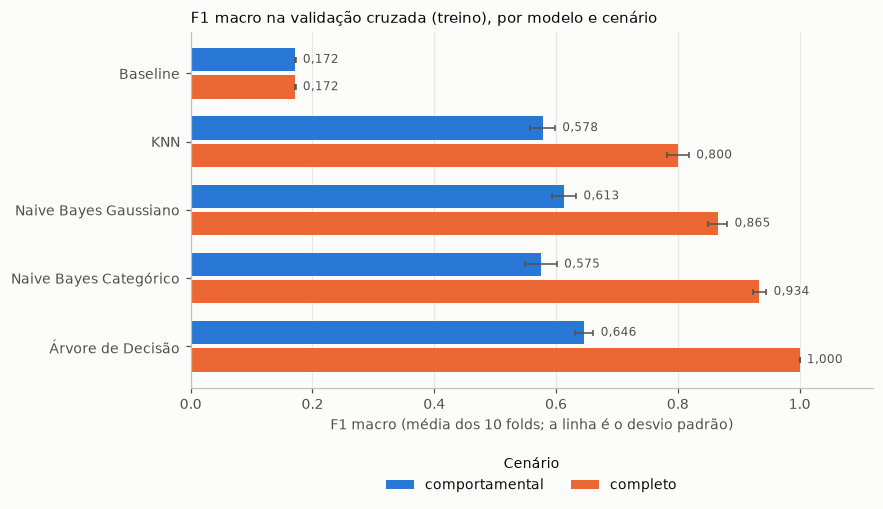

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cv_comparison(resultados_cv, REFIT, ax=ax)
ax.set_title("F1 macro na validação cruzada (treino), por modelo e cenário")
salvar(fig, "06_comparacao_cv")

**Resultado:**

- **Todos os modelos superam o baseline com folga.** O baseline acerta 52,5% só prevendo `Moderate Debt`, mas tem F1 macro de 0,172 e acurácia balanceada de 0,250, porque nunca acerta as outras três classes.
- **Cenário comportamental:** a árvore de decisão tem o maior F1 macro (0,646), seguida do Naive Bayes Gaussiano (0,613), do KNN (0,578) e do Naive Bayes Categórico (0,575). A diferença entre a árvore e o Gaussiano (0,033) é cerca de duas vezes o desvio padrão entre os folds, mas é uma estimativa de um único experimento, não um teste estatístico.
- **Cenário completo:** a árvore acerta 100% dos registros em todos os folds, porque reproduz a regra encontrada na validação (etapa 1) com `total_sleep_hours` e `next_day_fatigue_score`. Os outros modelos também sobem muito: de 0,22 (KNN) a 0,36 (Naive Bayes Categórico) a mais de F1 macro. Essa diferença entre os cenários é o efeito do vazamento de informação.
- **Naive Bayes Gaussiano ou Categórico:** no cenário comportamental, o Gaussiano é melhor (0,613 × 0,575). No completo, o Categórico é melhor (0,934 × 0,865), porque as faixas capturam os limiares da regra do alvo (ex.: `total_sleep_hours` ≥ 7,75), que uma distribuição normal por classe não representa bem.

## 4. Melhores hiperparâmetros

In [9]:
def formatar(params):
    """Hiperparâmetros como texto, sem o prefixo do passo do pipeline."""
    return ", ".join(f"{k.split('__')[1]}={v:g}" if isinstance(v, float) else f"{k.split('__')[1]}={v}"
                     for k, v in params.items())


melhores = pd.DataFrame(
    [{"cenário": cenario, "modelo": MODEL_NAMES[nome], "melhores hiperparâmetros": formatar(busca.best_params_)}
     for (cenario, nome), busca in buscas.items() if nome != "baseline"]
).set_index(["cenário", "modelo"])
with pd.option_context("display.max_colwidth", None):
    display(melhores)

melhores hiperparâmetros
cenário        modelo                                                                                              
comportamental KNN                             n_neighbors=5, weights=uniform, log_transform=False, scaler=standard
               Naive Bayes Gaussiano                                       var_smoothing=1e-05, log_transform=False
               Naive Bayes Categórico                                                          alpha=0.1, n_bins=15
               Árvore de Decisão       class_weight=None, max_depth=6, min_samples_leaf=20, nominal_encoding=onehot
completo       KNN                            n_neighbors=21, weights=distance, log_transform=True, scaler=standard
               Naive Bayes Gaussiano                                       var_smoothing=0.0001, log_transform=True
               Naive Bayes Categórico                                                        alpha=0.001, n_bins=20
               Árvore de Decisão       class_weight=None, max_depth=3, min_samples_leaf=1, nominal_encoding=ordinal

Para ver como o F1 macro varia com os principais hiperparâmetros, os gráficos abaixo fixam os demais no melhor valor (cenário comportamental):

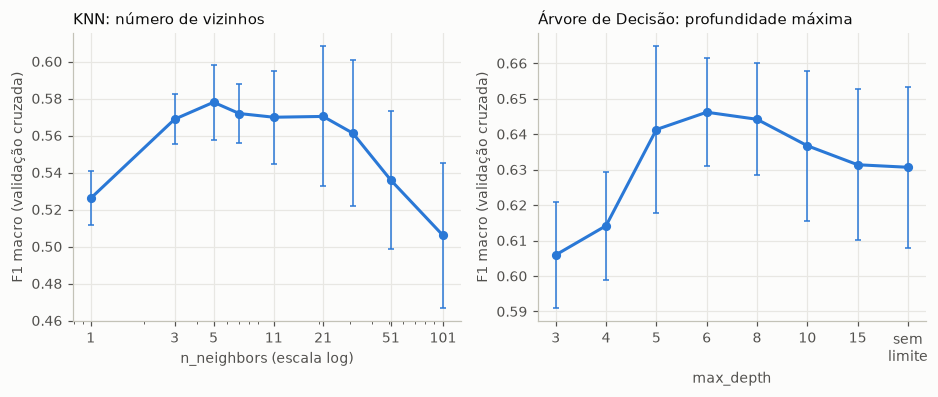

In [10]:
def curva(busca, parametro):
    """F1 macro médio (e desvio) em função de um hiperparâmetro, com os demais fixos no melhor valor."""
    resultados = busca.cv_results_
    fixos = {k: v for k, v in busca.best_params_.items() if k != parametro}
    indices = [i for i, params in enumerate(resultados["params"])
               if all(params[k] == v for k, v in fixos.items())]
    return pd.DataFrame({
        "valor": [resultados["params"][i][parametro] for i in indices],
        "media": resultados[f"mean_test_{REFIT}"][indices],
        "dp": resultados[f"std_test_{REFIT}"][indices],
    })


fig, eixos = plt.subplots(1, 2, figsize=(10, 3.4))
cor = SCENARIO_COLORS["comportamental"]

knn = curva(buscas["comportamental", "knn"], "model__n_neighbors")
eixos[0].errorbar(knn["valor"], knn["media"], yerr=knn["dp"], color=cor, lw=2,
                  marker="o", ms=5, capsize=2, elinewidth=1)
eixos[0].set_xscale("log")
eixos[0].set_xticks([1, 3, 5, 11, 21, 51, 101], ["1", "3", "5", "11", "21", "51", "101"])
eixos[0].set_title("KNN: número de vizinhos")
eixos[0].set_xlabel("n_neighbors (escala log)")

arvore = curva(buscas["comportamental", "tree"], "model__max_depth")
profundidades = ["sem\nlimite" if pd.isna(v) else str(int(v)) for v in arvore["valor"]]
eixos[1].errorbar(profundidades, arvore["media"], yerr=arvore["dp"], color=cor, lw=2,
                  marker="o", ms=5, capsize=2, elinewidth=1)
eixos[1].set_title("Árvore de Decisão: profundidade máxima")
eixos[1].set_xlabel("max_depth")

for ax in eixos:
    ax.set_ylabel("F1 macro (validação cruzada)")
salvar(fig, "06_curvas_hiperparametros")

**Resultado:**

- **KNN:** no cenário comportamental, o melhor é usar 5 vizinhos. Com 1 vizinho, o modelo segue o ruído de cada registro (F1 macro de 0,526); a partir de cerca de 30, as vizinhanças ficam dominadas por `Moderate Debt`, as classes menores perdem a votação e o F1 macro cai (0,506 com 101 vizinhos).
- **Escala do KNN:** a padronização (z-score) venceu o min-max nos dois cenários, o que combina com a presença de outliers reais, que comprimem as escalas do min-max.
- **`log1p`:** não melhorou o KNN nem o Naive Bayes Gaussiano no cenário comportamental. No cenário completo, que inclui a latência do sono (também assimétrica), as melhores combinações dos dois usam `log1p`.
- **Naive Bayes Gaussiano:** `var_smoothing` de 10⁻⁵ (comportamental) e 10⁻⁴ (completo), bem acima do padrão (10⁻⁹). A suavização maior compensa atributos com pouca variação dentro de uma classe, como as colunas one-hot.
- **Naive Bayes Categórico:** 15 faixas com `alpha` de 0,1 no cenário comportamental. No completo, o melhor ficou no limite da grade (20 faixas, `alpha` de 0,001): mais faixas aproximam melhor os limiares da regra do alvo. Como esse cenário serve só de comparação e já chega a 0,934, a grade não foi ampliada.
- **Árvore de Decisão:** one-hot nas nominais, profundidade 6 e pelo menos 20 registros por folha no cenário comportamental. O F1 macro sobe até a profundidade 6 e depois cai devagar (0,631 sem limite), sinal de que a árvore começa a se ajustar demais ao treino.
- **Codificação das nominais na árvore:** com one-hot, o melhor F1 macro é 0,646; com códigos inteiros, 0,632 (profundidade 8). Com códigos inteiros, a curva da profundidade também era irregular (0,558 com profundidade 4, abaixo dos 0,606 com profundidade 3), porque `Healthcare / Shift Worker`, a ocupação que mais se diferencia, fica no meio da ordem alfabética e precisa de dois cortes para ser isolada. Com one-hot, essa queda desaparece. No cenário completo, 3 níveis bastam, o mesmo número de limiares da regra do alvo.
- **`class_weight="balanced"`:** não foi escolhido. Na melhor combinação com pesos balanceados, a acurácia balanceada sobe (0,676 × 0,625), mas o F1 macro cai (0,612 × 0,646): a árvore passa a prever as classes raras com mais frequência e erra mais nelas.

## 5. Avaliação final no conjunto de teste

O conjunto de teste é usado só para a avaliação final. Cada pipeline final, já reajustado no treino inteiro com os melhores hiperparâmetros, prevê o teste, e nada mais é ajustado depois disso.

In [11]:
test = load_test()
X_test, y_test = test.drop(columns=TARGET), test[TARGET]
print(f"Teste: {X_test.shape[0]:,} linhas × {X_test.shape[1]} colunas")

previsoes = {}
linhas = []
for (cenario, nome), busca in buscas.items():
    with ignore_bin_warnings():
        previsoes[cenario, nome] = busca.predict(X_test)
    linhas.append({"cenário": cenario, "modelo": MODEL_NAMES[nome], **test_scores(y_test, previsoes[cenario, nome])})
resultados_teste = pd.DataFrame(linhas)

tabela_teste = resultados_teste.set_index(["cenário", "modelo"]).round(3)
tabela_teste.columns = list(METRIC_NAMES.values())
tabela_teste

Teste: 1,700 linhas × 17 colunas


Acurácia  Acurácia balanceada  F1 macro
cenário        modelo                                                         
comportamental Baseline                   0.525                0.250     0.172
               KNN                        0.648                0.533     0.563
               Naive Bayes Gaussiano      0.701                0.625     0.637
               Naive Bayes Categórico     0.690                0.553     0.594
               Árvore de Decisão          0.713                0.623     0.646
completo       Baseline                   0.525                0.250     0.172
               KNN                        0.830                0.770     0.795
               Naive Bayes Gaussiano      0.870                0.899     0.859
               Naive Bayes Categórico     0.956                0.961     0.936
               Árvore de Decisão          1.000                1.000     1.000

Diferença entre o F1 macro no teste e na validação cruzada. Valores próximos de zero indicam que a estimativa da validação cruzada se confirmou em dados novos:

In [12]:
comparacao = resultados_cv[["cenário", "modelo", "cv_f1_macro", "cv_f1_macro_dp"]].merge(
    resultados_teste[["cenário", "modelo", "teste_f1_macro"]], on=["cenário", "modelo"])
comparacao["diferença"] = comparacao["teste_f1_macro"] - comparacao["cv_f1_macro"]
comparacao.set_index(["cenário", "modelo"]).round(3)

cv_f1_macro  cv_f1_macro_dp  teste_f1_macro  diferença
cenário        modelo                                                                        
comportamental Baseline                      0.172           0.000           0.172      0.000
               KNN                           0.578           0.020           0.563     -0.015
               Naive Bayes Gaussiano         0.613           0.020           0.637      0.023
               Naive Bayes Categórico        0.575           0.026           0.594      0.019
               Árvore de Decisão             0.646           0.015           0.646     -0.001
completo       Baseline                      0.172           0.000           0.172      0.000
               KNN                           0.800           0.018           0.795     -0.005
               Naive Bayes Gaussiano         0.865           0.016           0.859     -0.006
               Naive Bayes Categórico        0.934           0.011           0.936      0.002
               Árvore de Decisão             1.000           0.000           1.000      0.000

**Resultado:**

- **O teste ficou próximo da validação cruzada.** As diferenças de F1 macro ficam entre −0,015 e +0,023, da ordem de um desvio padrão entre os folds. Isso não prova a ausência de sobreajuste: o melhor resultado de uma busca de hiperparâmetros tende a ser um pouco otimista, e o teste continua sendo a avaliação final.
- **Cenário comportamental:** no teste, a árvore (0,646) e o Naive Bayes Gaussiano (0,637) têm desempenhos próximos no F1 macro, e os dois acertam cerca de 70% dos registros (71,3% e 70,1%), contra 52,5% do baseline. O KNN continua sendo o mais fraco (0,563).
- **Revisão da árvore:** a opção de one-hot nas nominais da árvore foi incluída depois de uma revisão do método e escolhida só pela validação cruzada. O conjunto de teste já tinha sido usado uma vez com a versão anterior da grade, em que a árvore usava só códigos inteiros (F1 macro de 0,634 no teste).
- **Cenário completo:** a árvore volta a acertar 100% dos registros, e a ordem dos modelos é a mesma da validação cruzada.

## 6. Matrizes de confusão no teste (cenário comportamental)

Cada linha soma 100%: mostra para quais classes os registros de cada classe real foram previstos.

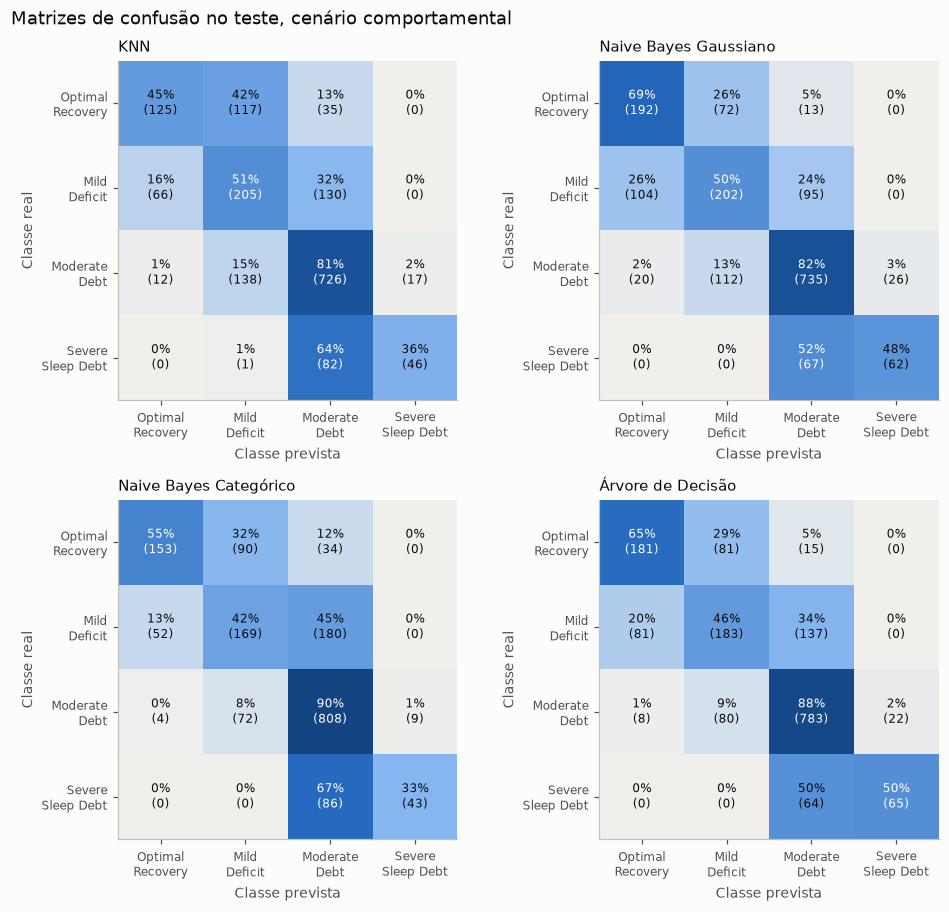

In [13]:
fig, eixos = plt.subplots(2, 2, figsize=(9, 8.4))
for ax, nome in zip(eixos.flat, ["knn", "gaussian_nb", "categorical_nb", "tree"]):
    plot_confusion_matrix(y_test, previsoes["comportamental", nome], ax=ax, title=MODEL_NAMES[nome])
fig.suptitle("Matrizes de confusão no teste, cenário comportamental", x=0.02, ha="left")
fig.tight_layout()
salvar(fig, "06_matrizes_confusao")

**Resultado:**

- **Quase todos os erros ficam entre classes vizinhas.** Como as classes são ordenadas, os modelos confundem principalmente `Optimal Recovery` com `Mild Deficit`, `Mild Deficit` com `Moderate Debt` e `Moderate Debt` com `Severe Sleep Debt`. Nenhum modelo prevê `Severe Sleep Debt` para um registro de `Optimal Recovery` ou de `Mild Deficit`.
- **A identificação dos casos de `Severe Sleep Debt` ainda é limitada:** a árvore identifica 50% dos casos, o Naive Bayes Gaussiano 48%, o KNN 36% e o Naive Bayes Categórico 33%; quase todo o restante é previsto como `Moderate Debt`.
- **`Mild Deficit` tem o menor F1 nos dois modelos e a menor revocação na árvore (46%):** fica entre `Optimal Recovery` e `Moderate Debt`, e os modelos erram para os dois lados.
- **`Moderate Debt`**, a classe majoritária, tem de 81% a 90% de acerto. Em `Optimal Recovery`, o Naive Bayes Gaussiano é o melhor (69%).
- Com os atributos de perfil e de antes de dormir, as classes vizinhas se sobrepõem. O alvo é definido pelas horas de sono e pela fadiga do dia seguinte, e os hábitos antes de dormir explicam só parte delas.

## 7. Salvar os resultados

As métricas da validação cruzada e do teste vão para `reports/metrics/resultados.csv`, junto com os melhores hiperparâmetros em JSON. Com eles, a etapa 7 recria qualquer modelo com `build_pipeline(nome, colunas, **parametros)`, sem repetir a busca.

In [14]:
resultados = resultados_cv.merge(resultados_teste, on=["cenário", "modelo"])
resultados.insert(2, "algoritmo", [nome for _, nome in buscas])
resultados["parametros"] = [
    json.dumps({k: (v.item() if isinstance(v, np.generic) else v) for k, v in busca.best_params_.items()})
    for busca in buscas.values()
]
RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)
resultados.to_csv(RESULTS_PATH, index=False)
pd.read_csv(RESULTS_PATH).head(3)

,cenário,modelo,algoritmo,cv_acuracia,cv_acuracia_dp,cv_acuracia_balanceada,cv_acuracia_balanceada_dp,cv_f1_macro,cv_f1_macro_dp,teste_acuracia,teste_acuracia_balanceada,teste_f1_macro,parametros
0,comportamental,Baseline,baseline,0.524853,0.000441,0.250000,0.000000,0.172099,0.000095,0.525294,0.250000,0.172194,{}
1,comportamental,KNN,knn,0.651471,0.015743,0.544007,0.021267,0.577990,0.020318,0.648235,0.533016,0.563443,"{""model__n_neighbors"": 5, ""model__weights"": ""u..."
2,comportamental,Naive Bayes Gaussiano,gaussian_nb,0.680735,0.012590,0.605368,0.019959,0.613427,0.019552,0.700588,0.625142,0.636908,"{""model__var_smoothing"": 9.999999999999999e-06..."


Conferência: os pipelines recriados a partir do arquivo, e ajustados no treino, fazem as mesmas previsões no teste.

In [15]:
salvos = pd.read_csv(RESULTS_PATH)
for linha in salvos.itertuples():
    pipeline = build_pipeline(linha.algoritmo, FEATURE_SETS[linha.cenário], **json.loads(linha.parametros))
    with ignore_bin_warnings():
        recriado = pipeline.fit(X_train, y_train).predict(X_test)
    assert (recriado == previsoes[linha.cenário, linha.algoritmo]).all()
print(f"Os {len(salvos)} pipelines recriados reproduzem as previsões.")

Os 10 pipelines recriados reproduzem as previsões.


## Resumo

- **Validação:** 10 folds estratificados, os mesmos para todos os modelos e cenários, com os hiperparâmetros escolhidos pelo F1 macro. As opções do pré-processamento (`log1p`, escala, `n_bins` e a codificação das nominais na árvore) foram ajustadas junto com os hiperparâmetros dos modelos.
- **Cenário comportamental (principal):** a árvore de decisão com one-hot (F1 macro de 0,646 na validação cruzada e no teste) e o Naive Bayes Gaussiano (0,613 e 0,637) são os melhores. A árvore fica à frente na validação cruzada, e os dois têm desempenhos próximos no teste. Os dois acertam cerca de 70% dos registros, contra 52,5% do baseline. O KNN e o Naive Bayes Categórico ficam um pouco atrás.
- **Naive Bayes:** o Gaussiano é a melhor versão no cenário principal; o Categórico, no completo.
- **Cenário completo (comparação):** a árvore chega a 100% de acerto, e os outros modelos ganham de 0,22 a 0,36 de F1 macro. É o efeito do vazamento das colunas do sono e do dia seguinte.
- **Teste:** usado só na avaliação final, ficou próximo das estimativas da validação cruzada (diferenças de no máximo 0,023).
- **Arquivos:** métricas e hiperparâmetros em `reports/metrics/resultados.csv`; figuras `06_comparacao_cv`, `06_curvas_hiperparametros` e `06_matrizes_confusao` em `reports/figures/`.